In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os

In [2]:
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)

pd.set_option("display.max_columns", None)

In [7]:
df= pd.read_csv("retail_sales_dataset.csv")

In [8]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [9]:
df.shape

(1000, 9)

In [11]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [15]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [16]:
df.describe(include="object")

,Date,Customer ID,Gender,Product Category
count,1000,1000,1000,1000
unique,345,1000,2,3
top,2023-05-16,CUST001,Female,Clothing
freq,11,1,510,351


In [18]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [19]:
missing_percentage= (df.isnull().mean() * 100)
print(missing_percentage)

Transaction ID      0.0
Date                0.0
Customer ID         0.0
Gender              0.0
Age                 0.0
Product Category    0.0
Quantity            0.0
Price per Unit      0.0
Total Amount        0.0
dtype: float64


In [23]:
df["Date"] = pd.to_datetime(df["Date"],errors="coerce")

In [27]:
numeric_columns= ["Age",
                  "Quantity",
                  "Price per Unit",
                  "Total Amount"]


for col in numeric_columns:
    df[col] = pd.to_numeric(df[col],
                            errors= "coerce")

In [28]:
df[numeric_columns].describe()

,Age,Quantity,Price per Unit,Total Amount
count,1000.00000,1000.000000,1000.000000,1000.000000
mean,41.39200,2.514000,179.890000,456.000000
std,13.68143,1.132734,189.681356,559.997632
min,18.00000,1.000000,25.000000,25.000000
25%,29.00000,1.000000,30.000000,60.000000
50%,42.00000,3.000000,50.000000,135.000000
75%,53.00000,4.000000,300.000000,900.000000
max,64.00000,4.000000,500.000000,2000.000000


In [29]:
(df[numeric_columns] < 0).sum()

Age               0
Quantity          0
Price per Unit    0
Total Amount      0
dtype: int64

In [30]:
df["Age"]= df["Age"].fillna( df["Age"].median())

In [31]:
df = df.dropna(subset=["Date"])

In [32]:
print("Total Transactions:", len(df))

print("Total Sales:", df["Total Amount"].sum())

print("Average Transaction:",
      df["Total Amount"].mean())

print("Median Transaction:",
      df["Total Amount"].median())

print("Maximum Transaction:",
      df["Total Amount"].max())

print("Minimum Transaction:",
      df["Total Amount"].min())

Total Transactions: 1000
Total Sales: 456000
Average Transaction: 456.0
Median Transaction: 135.0
Maximum Transaction: 2000
Minimum Transaction: 25


In [33]:
category_sales= (df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False))
category_sales

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

In [34]:
print("Top Selling Category:")
print(category_sales.idxmax())

Top Selling Category:
Electronics


In [35]:
gender_sales = (
    df.groupby("Gender")["Total Amount"]
    .sum()
)

print(gender_sales)

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


In [39]:
#print("Best Sales Month:", monthly_sales.idxmax())

In [40]:
print("Average Age:", df["Age"].mean())

print("Youngest Customer:", df["Age"].min())

print("Oldest Customer:", df["Age"].max())

Average Age: 41.392
Youngest Customer: 18
Oldest Customer: 64


In [41]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 20, 30, 40, 50, 100],
    labels=[
        "Below 20",
        "20-30",
        "30-40",
        "40-50",
        "50+"
    ]
)

In [42]:
print(df["Age Group"].value_counts().sort_index())

Age Group
Below 20     63
20-30       210
30-40       193
40-50       221
50+         313
Name: count, dtype: int64


In [43]:
df["Year"] = df["Date"].dt.year

df["Month"] = df["Date"].dt.month

df["Month Name"] = df["Date"].dt.month_name()

df["Day"] = df["Date"].dt.day

df["Day Name"] = df["Date"].dt.day_name()

In [45]:
df["Revenue"] = df["Quantity"] * df["Price per Unit"]

In [46]:
df[[
    "Quantity",
    "Price per Unit",
    "Total Amount",
    "Revenue"
]].head()

,Quantity,Price per Unit,Total Amount,Revenue
0,3,50,150,150
1,2,500,1000,1000
2,1,30,30,30
3,1,500,500,500
4,2,50,100,100


In [47]:
np.allclose(
    df["Revenue"],
    df["Total Amount"],
    equal_nan=True
)

True

outlier detection

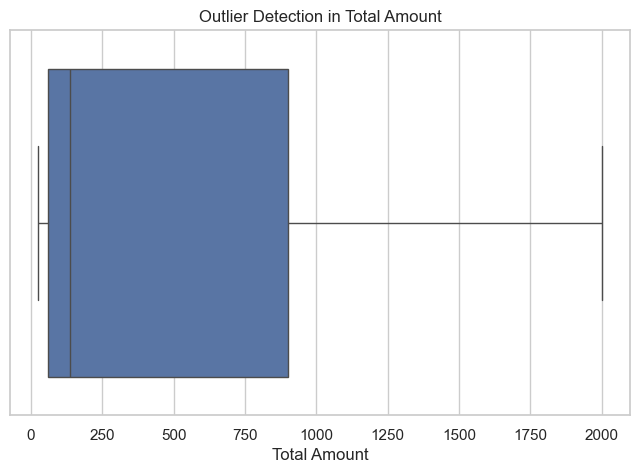

In [48]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x=df["Total Amount"]
)

plt.title("Outlier Detection in Total Amount")
plt.xlabel("Total Amount")

plt.show()

In [49]:
Q1 = df["Total Amount"].quantile(0.25)

Q3 = df["Total Amount"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: -1200.0
Upper Limit: 2160.0


In [50]:
outliers = df[
    (df["Total Amount"] < lower_limit) |
    (df["Total Amount"] > upper_limit)
]

print("Total Outliers:", len(outliers))

Total Outliers: 0


In [51]:
df["Total Amount Clipped"] = (
    df["Total Amount"].clip(
        lower=lower_limit,
        upper=upper_limit
    )
)

In [52]:
print("Original Summary:")
print(df["Total Amount"].describe())

print("\nClipped Summary:")
print(df["Total Amount Clipped"].describe())

Original Summary:
count    1000.000000
mean      456.000000
std       559.997632
min        25.000000
25%        60.000000
50%       135.000000
75%       900.000000
max      2000.000000
Name: Total Amount, dtype: float64

Clipped Summary:
count    1000.000000
mean      456.000000
std       559.997632
min        25.000000
25%        60.000000
50%       135.000000
75%       900.000000
max      2000.000000
Name: Total Amount Clipped, dtype: float64


Monthly Sales Trend — Line Plot

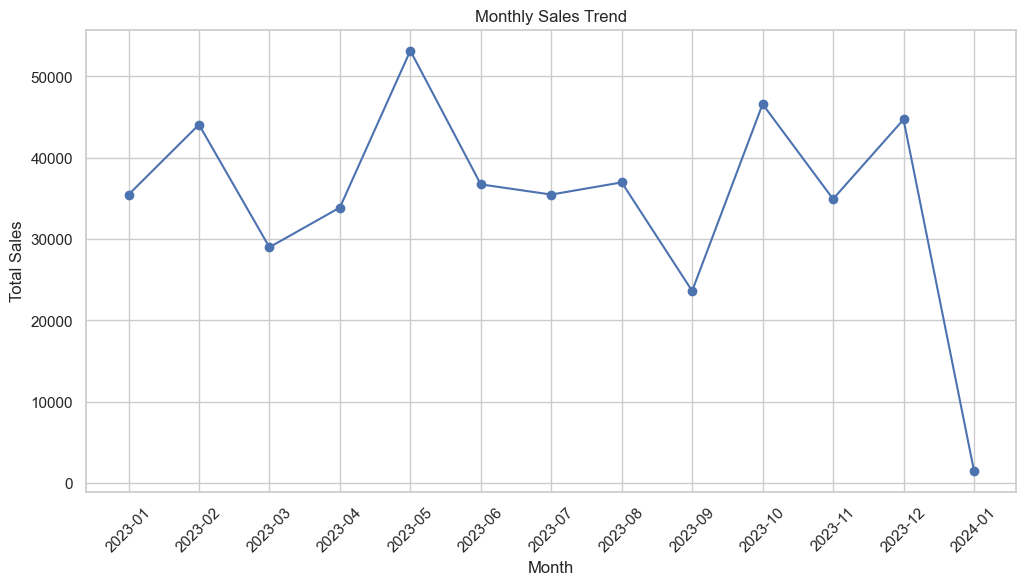

In [ ]:
monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))["Total Amount"]
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"s
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.grid(True)

plt.show()

Category-wise Sales — Bar Plot

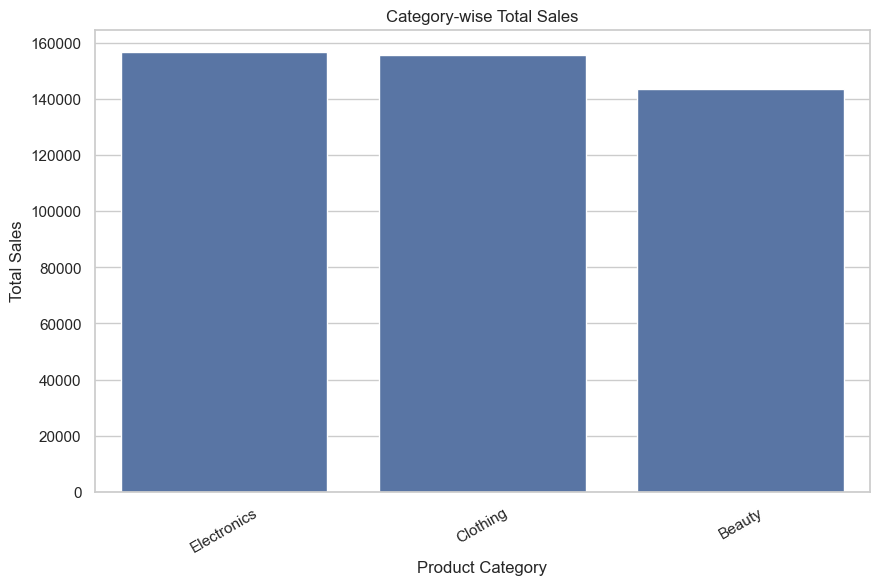

In [61]:
category_sales = (
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Category-wise Total Sales")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=30)

plt.show()

Gender-wise Transactions — Count Plot

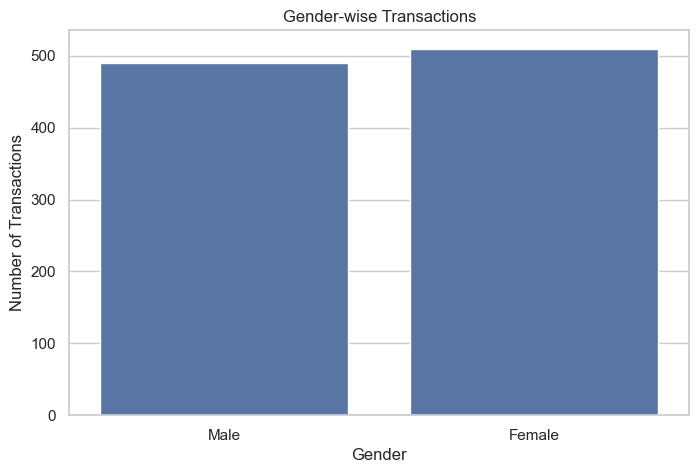

In [62]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Gender"
)

plt.title("Gender-wise Transactions")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")

plt.show()

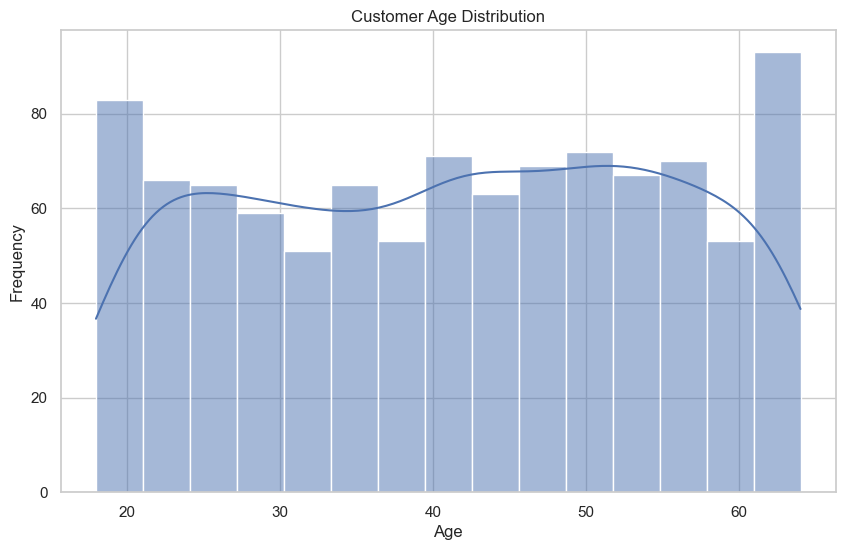

In [63]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

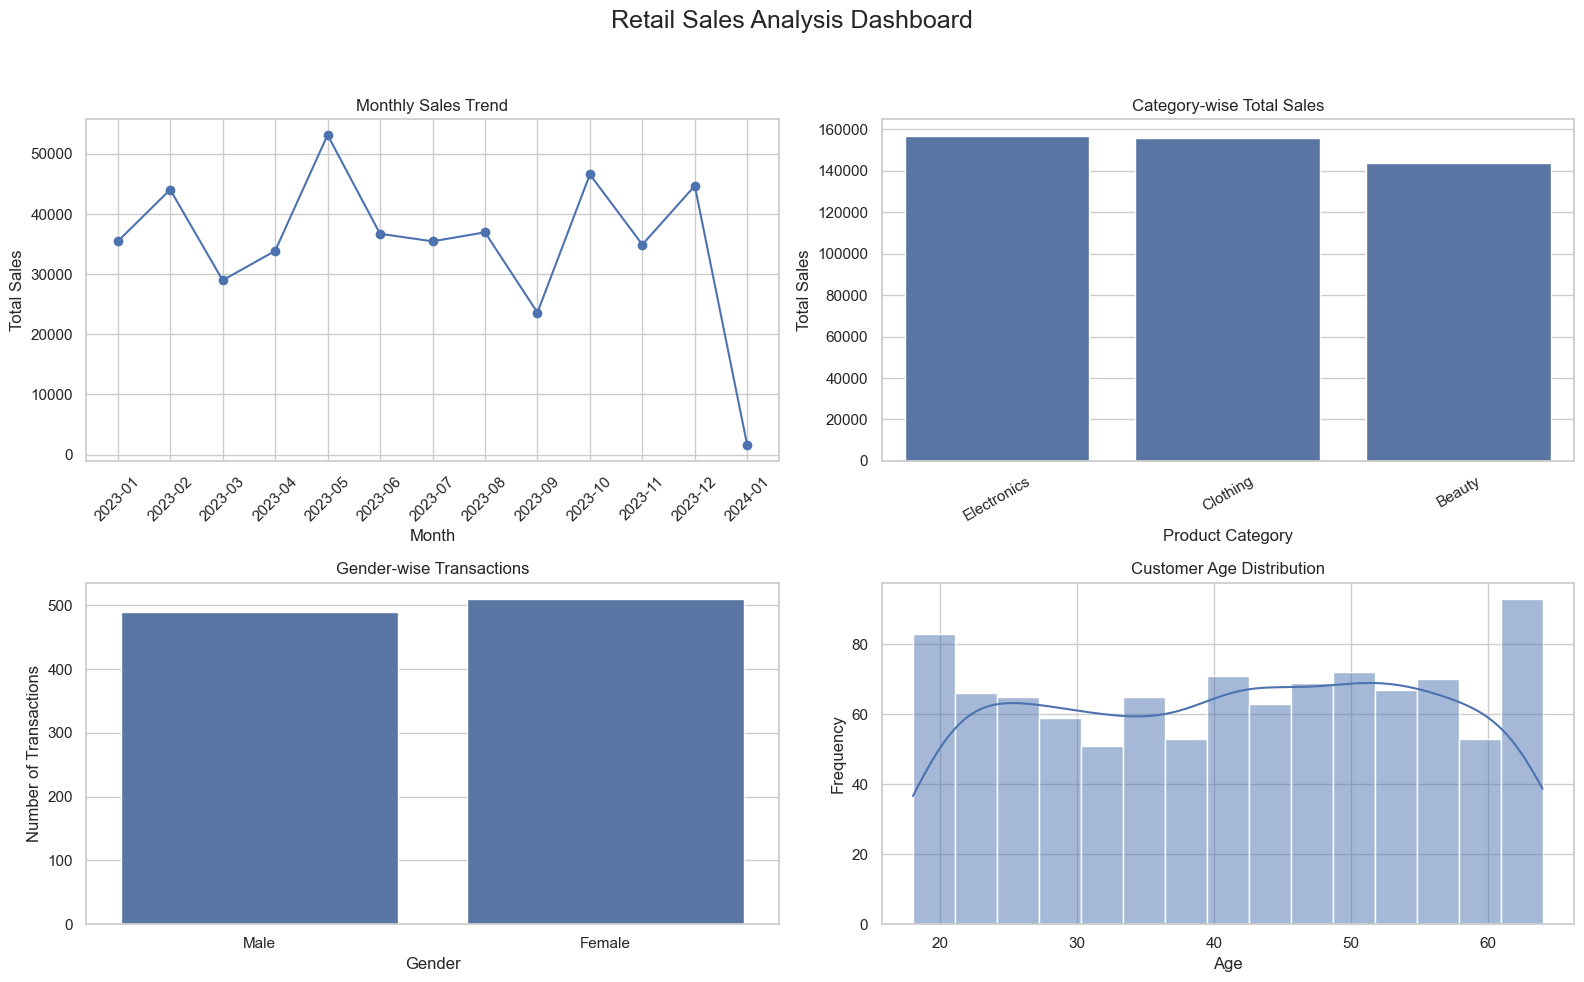

In [64]:
# Create output folder
os.makedirs("../outputs", exist_ok=True)

# Create 2x2 dashboard
fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10)
)

# Chart 1: Monthly Sales Trend
monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))["Total Amount"]
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

axes[0, 0].plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

axes[0, 0].set_title("Monthly Sales Trend")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Total Sales")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(True)


# Chart 2: Category-wise Sales
category_sales = (
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

sns.barplot(
    x=category_sales.index,
    y=category_sales.values,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Category-wise Total Sales")
axes[0, 1].set_xlabel("Product Category")
axes[0, 1].set_ylabel("Total Sales")
axes[0, 1].tick_params(axis="x", rotation=30)


# Chart 3: Gender-wise Transactions
sns.countplot(
    data=df,
    x="Gender",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Gender-wise Transactions")
axes[1, 0].set_xlabel("Gender")
axes[1, 0].set_ylabel("Number of Transactions")


# Chart 4: Customer Age Distribution
sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Customer Age Distribution")
axes[1, 1].set_xlabel("Age")
axes[1, 1].set_ylabel("Frequency")


# Main dashboard title
fig.suptitle(
    "Retail Sales Analysis Dashboard",
    fontsize=18
)

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Save dashboard image
plt.savefig(
    "../outputs/retail_sales_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

# Display dashboard
plt.show()

In [65]:
total_sales = df["Total Amount"].sum()

total_transactions = len(df)

average_transaction = df["Total Amount"].mean()

top_category = category_sales.idxmax()

top_category_sales = category_sales.max()

best_month = monthly_sales.idxmax()

average_age = df["Age"].mean()

print("===== BUSINESS INSIGHTS =====")

print("Total Sales:", total_sales)

print("Total Transactions:", total_transactions)

print("Average Transaction:", average_transaction)

print("Top Selling Category:", top_category)

print("Top Category Sales:", top_category_sales)

print("Best Sales Month:", best_month)

print("Average Customer Age:", average_age)

===== BUSINESS INSIGHTS =====
Total Sales: 456000
Total Transactions: 1000
Average Transaction: 456.0
Top Selling Category: Electronics
Top Category Sales: 156905
Best Sales Month: 2023-05
Average Customer Age: 41.392


In [66]:
df.to_csv(
    "../outputs/cleaned_retail_sales.csv",
    index=False
)